# 02 — Le bigramme en `nn.Module` : embedding, cross-entropy, SGD vs AdamW

**Chapitre 2** · durée conseillée : 35 min · CPU uniquement

![Parcours](figures/00_parcours.svg)

Au chapitre 1, nous avions écrit le bigramme « à la main » : une matrice `W` de taille `(27, 27)`, un one-hot, un softmax, une NLL, et `W -= lr * W.grad`. Nous réécrivons **exactement le même modèle** avec les outils standards de PyTorch, ceux que nous utiliserons pour le GPT :

| Chapitre 1 (à la main) | Chapitre 2 (PyTorch) |
|---|---|
| `W = torch.randn(27, 27, requires_grad=True)` | `nn.Embedding(V, V)` dans un `nn.Module` |
| `one_hot(x) @ W` | `embedding(x)` |
| `softmax` + `-log(p).mean()` | `F.cross_entropy(logits, y)` |
| `W -= lr * W.grad` | `optimizer.step()` (SGD ou **AdamW**) |

**À la fin de ce notebook, vous saurez :**
1. écrire un modèle comme sous-classe de `nn.Module` ;
2. expliquer pourquoi `nn.Embedding(V, V)` *est* la matrice `W` du chapitre 1 ;
3. expliquer ce que calcule `F.cross_entropy` et pourquoi on lui donne des **logits** ;
4. comparer **SGD** et **AdamW** et expliquer pourquoi AdamW est le choix par défaut ;
5. entraîner le bigramme 120 pas et générer 120 caractères.

In [1]:
# Préparation : imports et module partagé du chapitre
import math
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

import minigpt  # fichier minigpt.py, à côté de ce notebook
torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| périphérique :", device)

CORPUS = "shakespeare"
texte, tok, train_data, val_data = minigpt.preparer_donnees(CORPUS)
V = tok.vocab_size
print(f"{CORPUS} : V = {V}, train = {len(train_data):,} caractères")

PyTorch 2.14.1+cu130 | périphérique : cpu
shakespeare : V = 65, train = 1,003,854 caractères


## 1. `nn.Module` : la « boîte » qui contient les paramètres

Un modèle PyTorch est une classe qui hérite de `nn.Module`. Deux méthodes suffisent :

- `__init__` : on **déclare les couches** (et donc leurs paramètres) ;
- `forward` : on décrit le **calcul** des entrées vers les sorties.

En échange, `nn.Module` nous offre gratuitement :
- `model(x)` appelle `model.forward(x)` ;
- `model.parameters()` liste **tous** les paramètres entraînables, même ceux des sous-couches : c'est ce qu'on donnera à l'optimiseur ;
- `model.train()` / `model.eval()` (utile pour le dropout, notebook 06), `model.to(device)`, la sauvegarde, etc.

In [2]:
class MiniExemple(nn.Module):
    def __init__(self):
        super().__init__()
        self.W = nn.Parameter(torch.randn(3, 3))   # un paramètre « à la main »
        self.couche = nn.Linear(3, 2)              # une couche qui contient ses propres paramètres

    def forward(self, x):
        return self.couche(x @ self.W)

m = MiniExemple()
for nom, p in m.named_parameters():
    print(f"{nom:15s} {tuple(p.shape)}  requires_grad={p.requires_grad}")
print("sortie :", m(torch.ones(1, 3)).shape)

W               (3, 3)  requires_grad=True
couche.weight   (2, 3)  requires_grad=True
couche.bias     (2,)  requires_grad=True
sortie : torch.Size([1, 2])


## 2. `nn.Embedding(V, V)` : la matrice `W` du chapitre 1

![Le bigramme comme nn.Module](figures/02_bigramme.svg)

`nn.Embedding(V, D)` est une table de `V` lignes et `D` colonnes, initialisée au hasard (loi normale `N(0, 1)`). Lui donner un indice `i`, c'est **lire la ligne `i`**.

Au chapitre 1 nous avions montré que `one_hot(i) @ W` sélectionne la ligne `i` de `W`. `nn.Embedding` fait **la même chose sans construire le one-hot** : c'est plus rapide et plus économe en mémoire. Vérifions-le.

In [3]:
emb = nn.Embedding(V, V)
idx = torch.tensor([tok.stoi["e"], tok.stoi["h"], tok.stoi["e"]])

par_embedding = emb(idx)                                   # (3, V)
par_one_hot = F.one_hot(idx, num_classes=V).float() @ emb.weight   # (3, V)
par_indexation = emb.weight[idx]                           # (3, V)

print("forme :", tuple(par_embedding.shape))
print("embedding == one_hot @ W ?", torch.allclose(par_embedding, par_one_hot))
print("embedding == W[idx] ?     ", torch.allclose(par_embedding, par_indexation))
print("Deux 'e' -> deux fois la même ligne ?", torch.equal(par_embedding[0], par_embedding[2]))

forme : (3, 65)
embedding == one_hot @ W ? True
embedding == W[idx] ?      True
Deux 'e' -> deux fois la même ligne ? True


Dans le bigramme, la table a **V colonnes** : la ligne lue contient directement **un score par caractère suivant possible**. Ces scores s'appellent des **logits** : des nombres réels quelconques, qui ne deviennent des probabilités qu'après un softmax.

> Dans le GPT, nous utiliserons `nn.Embedding(V, C)` avec `C` ≠ `V` : la ligne lue ne sera plus une prédiction, mais un **vecteur de caractéristiques** de taille `C` que les couches suivantes transformeront.

### Le modèle bigramme

Dans ce notebook, l'entrée est un simple vecteur de `N` caractères (une position par exemple). Le notebook 03 l'étendra aux séquences `(B, T)`.

In [4]:
class BigramLanguageModel(nn.Module):

    def __init__(self, vocab_size):
        super().__init__()
        # Ligne i = les logits du caractère qui suit le caractère i.
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)        # (N,) -> (N, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits, targets)     # targets : (N,)
        return logits, loss

    @torch.no_grad()
    def generate(self, debut, max_new_tokens):
        sortie = [debut]
        for _ in range(max_new_tokens):
            logits, _ = self(torch.tensor([sortie[-1]]))   # (1, V) : seul le DERNIER caractère compte
            probs = F.softmax(logits, dim=-1)
            sortie.append(torch.multinomial(probs[0], num_samples=1).item())
        return sortie


torch.manual_seed(1337)
model = BigramLanguageModel(V)
print(model)
print("paramètres :", sum(p.numel() for p in model.parameters()), "=", V, "×", V)

BigramLanguageModel(
  (token_embedding_table): Embedding(65, 65)
)
paramètres : 4225 = 65 × 65


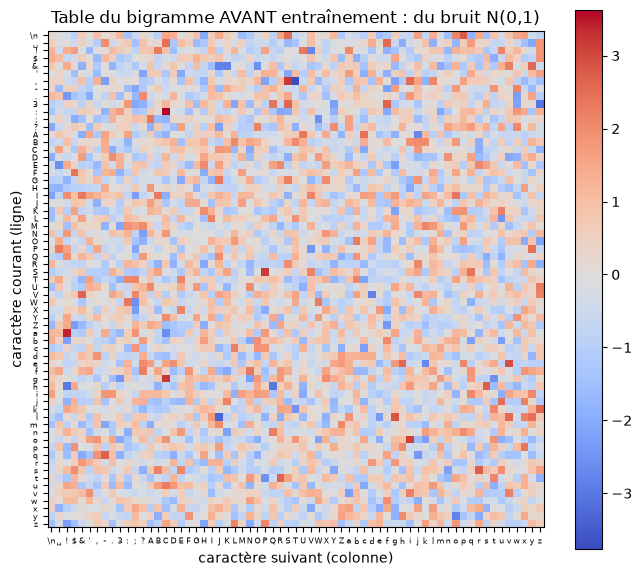

In [5]:
def heatmap(matrice, titre):
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(matrice.detach(), cmap="coolwarm")
    etiq = [{"\n": "\\n", " ": "␣"}.get(c, c) for c in tok.chars]
    ax.set_xticks(range(V), etiq, fontsize=6); ax.set_yticks(range(V), etiq, fontsize=6)
    ax.set_xlabel("caractère suivant (colonne)"); ax.set_ylabel("caractère courant (ligne)")
    ax.set_title(titre); fig.colorbar(im, ax=ax); plt.show()

heatmap(model.token_embedding_table.weight, "Table du bigramme AVANT entraînement : du bruit N(0,1)")

## 3. `F.cross_entropy` : softmax + NLL en une seule fonction

Au chapitre 1, la loss se calculait en quatre étapes :

$$\text{logits} \xrightarrow{\exp} \text{poids positifs} \xrightarrow{\div\,\Sigma} \text{probabilités} \xrightarrow{-\log p_{\text{vraie réponse}}\,,\ \text{moyenne}} \mathcal{L}$$

`F.cross_entropy(logits, targets)` fait **exactement** cela, en une ligne :

$$\mathcal{L} = -\frac{1}{N}\sum_{n=1}^{N} \log \frac{e^{\,\text{logits}[n,\,y_n]}}{\sum_{j} e^{\,\text{logits}[n,\,j]}}$$

Trois points à retenir :
1. On lui donne des **logits**, pas des probabilités (le softmax est fait à l'intérieur).
2. Les cibles sont des **indices** de classes (`torch.long`), pas des one-hot.
3. Formes attendues : logits `(N, V)` et cibles `(N,)`. Cette contrainte est la raison du *reshape* du notebook 03.

In [6]:
torch.manual_seed(0)
ix = torch.randint(len(train_data) - 1, (8,))
x, y = train_data[ix], train_data[ix + 1]           # 8 paires (caractère, suivant)
logits, loss = model(x, y)

# La même chose « à la main », comme au chapitre 1 :
probs = logits.exp() / logits.exp().sum(dim=1, keepdim=True)
p_vraie = probs[torch.arange(len(y)), y]
loss_main = -p_vraie.log().mean()

for c1, c2, p in zip(x, y, p_vraie):
    print(f"{tok.itos[c1.item()]!r:6} -> {tok.itos[c2.item()]!r:6}  p(vraie réponse) = {p.item():.4f}")
print(f"\nF.cross_entropy : {loss.item():.4f}")
print(f"à la main       : {loss_main.item():.4f}")

'e'    -> ' '     p(vraie réponse) = 0.0063
's'    -> 'i'     p(vraie réponse) = 0.0199
'h'    -> 'e'     p(vraie réponse) = 0.0074
'e'    -> 't'     p(vraie réponse) = 0.0285
','    -> ' '     p(vraie réponse) = 0.0114
'.'    -> '\n'    p(vraie réponse) = 0.0328
':'    -> '\n'    p(vraie réponse) = 0.0021
'\n'   -> 'M'     p(vraie réponse) = 0.0016

F.cross_entropy : 4.7440
à la main       : 4.7440


### Pourquoi ne pas tout faire à la main ? La stabilité numérique

`exp(1000)` dépasse la capacité d'un `float32` : le calcul « à la main » produit `inf`, puis `nan`. `F.cross_entropy` utilise l'identité $\log\sum_j e^{z_j} = m + \log\sum_j e^{z_j - m}$ (avec $m = \max_j z_j$) et ne déborde jamais.

In [7]:
logits_extremes = torch.tensor([[1000.0, 0.0, -1000.0]])
cible = torch.tensor([0])
p = logits_extremes.exp() / logits_extremes.exp().sum()
print("à la main       :", (-p[0, 0].log()).item())
print("F.cross_entropy :", F.cross_entropy(logits_extremes, cible).item())

à la main       : nan
F.cross_entropy : 0.0


### Quelle loss attendre au départ ?

Avec des logits nuls, toutes les probabilités vaudraient `1/V` et la loss `log V`. Notre table est initialisée avec `N(0, 1)` : les logits sont bruités, le modèle est **confiant à tort** sur certains caractères, et la loss initiale est un peu **plus haute** que `log V`.

In [8]:
@torch.no_grad()
def loss_val(model):
    """Loss sur TOUTES les paires (caractère, suivant) de la validation."""
    return model(val_data[:-1], val_data[1:])[1].item()

print(f"log(V)                  = {math.log(V):.3f}")
print(f"loss du modèle initial  = {loss_val(model):.3f}")

log(V)                  = 4.174
loss du modèle initial  = 4.724


## 4. Entraîner : 120 mises à jour

La boucle est celle du chapitre 1, avec deux différences :
- à chaque pas, on tire **256 paires au hasard** dans le texte au lieu d'utiliser tout le corpus (un *mini-batch*, détaillé au notebook 03) ;
- la mise à jour est faite par un **optimiseur** : `zero_grad()` → `backward()` → `step()`.

In [9]:
def paires_au_hasard(data, n=256):
    ix = torch.randint(len(data) - 1, (n,))
    return data[ix], data[ix + 1]


def entrainer(model, optimizer, pas=120):
    historique = []
    for _ in range(pas):
        x, y = paires_au_hasard(train_data)
        _, loss = model(x, y)                 # 1. forward + loss
        optimizer.zero_grad(set_to_none=True) # 2. effacer les anciens gradients
        loss.backward()                       # 3. calculer les nouveaux
        optimizer.step()                      # 4. mettre à jour les poids
        historique.append(loss.item())
    return historique


torch.manual_seed(1337)
model = BigramLanguageModel(V)
opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
h = entrainer(model, opt, pas=120)
print(f"loss : {h[0]:.3f} -> {h[-1]:.3f}   (validation : {loss_val(model):.3f})")
print(tok.decode(model.generate(tok.stoi["\n"], 120)))

loss : 4.745 -> 4.721   (validation : 4.584)

u!d?s&oCJ;SJAXxa;TvGSSaXiGr'T;.,.s:BMgX:C'P IBb?HdnDM&SP!Utgi,lyJhsgZdZ?yNX$C&DH:EOtRjK$ dlywOE;dbGvbwpC-o.SB!BX &ZyYV&k


**Presque rien n'a bougé.** Avec `lr = 1e-3`, chaque pas modifie les poids d'environ un millième : 120 pas ne suffisent pas pour une table de 4 225 nombres. Le texte généré est encore du bruit.

Avant de « monter le learning rate au hasard », comprenons ce que fait l'optimiseur.

---
## 5. SGD vs AdamW : comment les gradients deviennent des mises à jour

`loss.backward()` calcule, pour chaque poids $w$, sa dérivée $g = \partial \mathcal{L} / \partial w$. **L'optimiseur décide quoi en faire.**

### SGD (*stochastic gradient descent*)

C'est la règle du chapitre 1 :

$$w \leftarrow w - \eta\, g$$

- « stochastique » parce que $g$ est calculé sur un **mini-batch** tiré au hasard : c'est une estimation bruitée du vrai gradient ;
- **un seul** learning rate $\eta$ pour tous les poids ;
- la taille du pas est **proportionnelle au gradient** : un poids dont le gradient est minuscule ne bouge presque pas.

### Adam / AdamW

Adam garde, **pour chaque poids**, deux moyennes glissantes :

$$m \leftarrow \beta_1 m + (1-\beta_1)\,g \qquad\text{(direction moyenne : « momentum »)}$$
$$v \leftarrow \beta_2 v + (1-\beta_2)\,g^2 \qquad\text{(amplitude typique du gradient)}$$

puis met à jour avec

$$w \leftarrow w - \eta\,\frac{\hat m}{\sqrt{\hat v} + \varepsilon}$$

($\hat m$, $\hat v$ : versions corrigées du biais de démarrage, car $m$ et $v$ partent de 0.)

**Ce qu'il faut comprendre :** le rapport $\hat m / \sqrt{\hat v}$ est de l'ordre de **±1**, quelle que soit l'échelle du gradient. Chaque poids avance donc d'environ $\eta$ par pas : **la taille du pas ne dépend plus de la taille du gradient**, seulement de sa régularité.

### Le « W » de AdamW : *weight decay* découplé

AdamW ajoute un léger rappel des poids vers 0 : $w \leftarrow w - \eta\,\lambda\,w$, appliqué **séparément** de la mise à jour adaptative (Loshchilov & Hutter, 2019). Cela évite que des poids deviennent inutilement grands. Dans PyTorch, `AdamW` utilise $\lambda = 0{,}01$ par défaut.

Vérifions sur un seul poids que la formule ci-dessus est bien ce que fait PyTorch.

In [10]:
# Un seul pas d'AdamW calculé à la main, comparé à torch.optim.AdamW
w = torch.tensor([0.5], requires_grad=True)
opt = torch.optim.AdamW([w], lr=0.1, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.01)
g = torch.tensor([3.0])                    # imaginons ce gradient
w.grad = g.clone()
w_avant = w.item()
opt.step()

m = (1 - 0.9) * g;  v = (1 - 0.999) * g**2          # m et v partent de 0
m_hat = m / (1 - 0.9);  v_hat = v / (1 - 0.999)    # correction du biais (pas n°1)
w_main = w_avant * (1 - 0.1 * 0.01)                # weight decay découplé
w_main = w_main - 0.1 * m_hat / (v_hat.sqrt() + 1e-8)
print(f"PyTorch : {w.item():.6f} | à la main : {w_main.item():.6f}")
print("Le gradient valait 3, mais le pas vaut ≈ lr = 0.1 : Adam normalise l'amplitude.")

PyTorch : 0.399500 | à la main : 0.399500
Le gradient valait 3, mais le pas vaut ≈ lr = 0.1 : Adam normalise l'amplitude.


### Pourquoi cela compte pour notre bigramme

Regardons l'**échelle des gradients** de la table. Avec 256 paires par batch, une ligne de la table ne reçoit du gradient que si son caractère apparaît dans le batch, et la loss est une **moyenne** sur 256 exemples : les gradients sont minuscules.

In [11]:
torch.manual_seed(1337)
model = BigramLanguageModel(V)
x, y = paires_au_hasard(train_data)
_, loss = model(x, y)
loss.backward()
g = model.token_embedding_table.weight.grad
print(f"|gradient| moyen       : {g.abs().mean():.2e}")
print(f"|gradient| max         : {g.abs().max():.2e}")
print(f"lignes sans gradient   : {(g.abs().sum(1) == 0).sum().item()} / {V}")
print("Avec SGD et lr=1e-3, un poids bouge de ~1e-3 × 1e-4 = 1e-7 par pas !")

|gradient| moyen       : 4.33e-04
|gradient| max         : 3.05e-02
lignes sans gradient   : 27 / 65
Avec SGD et lr=1e-3, un poids bouge de ~1e-3 × 1e-4 = 1e-7 par pas !


### Expérience : même modèle, même initialisation, même données — seul l'optimiseur change

**Prédiction avant d'exécuter :** quel optimiseur atteindra la loss la plus basse en 120 pas ? Faut-il le même learning rate pour les deux ?

SGD   lr=1e-3 : loss train 4.868 | val 4.723
SGD   lr=1 : loss train 4.030 | val 4.049
SGD   lr=10 : loss train 2.731 | val 2.893
AdamW lr=1e-3 : loss train 4.721 | val 4.584
AdamW lr=1e-2 : loss train 3.634 | val 3.574
AdamW lr=1e-1 : loss train 2.348 | val 2.541


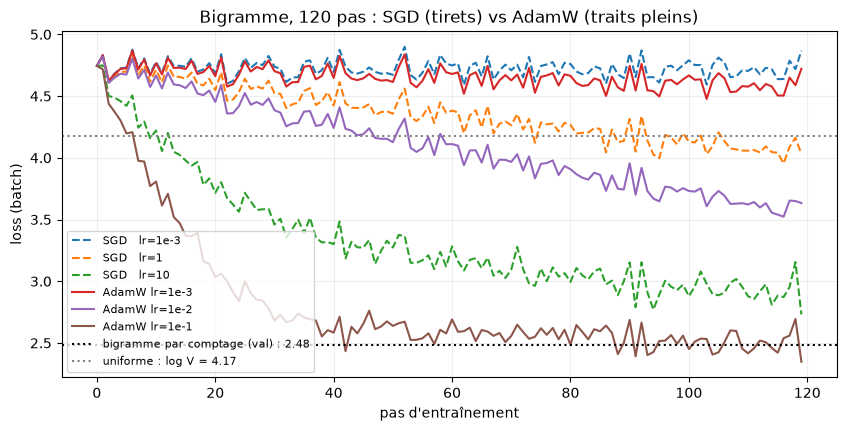

In [12]:
configs = {
    "SGD   lr=1e-3": lambda p: torch.optim.SGD(p, lr=1e-3),
    "SGD   lr=1":    lambda p: torch.optim.SGD(p, lr=1.0),
    "SGD   lr=10":   lambda p: torch.optim.SGD(p, lr=10.0),
    "AdamW lr=1e-3": lambda p: torch.optim.AdamW(p, lr=1e-3),
    "AdamW lr=1e-2": lambda p: torch.optim.AdamW(p, lr=1e-2),
    "AdamW lr=1e-1": lambda p: torch.optim.AdamW(p, lr=1e-1),
}
resultats, modeles = {}, {}
for nom, fabrique in configs.items():
    torch.manual_seed(1337)                      # même initialisation ET mêmes batchs
    m = BigramLanguageModel(V)
    resultats[nom] = entrainer(m, fabrique(m.parameters()), pas=120)
    modeles[nom] = m
    print(f"{nom} : loss train {resultats[nom][-1]:.3f} | val {loss_val(m):.3f}")

# Référence : le meilleur bigramme possible, obtenu en COMPTANT (chapitre 1, avec lissage +1)
N = torch.ones(V, V)
N.index_put_((train_data[:-1], train_data[1:]), torch.ones(len(train_data) - 1), accumulate=True)
P = N / N.sum(1, keepdim=True)
loss_comptage = -P[val_data[:-1], val_data[1:]].log().mean().item()

fig, ax = plt.subplots(figsize=(10, 4.5))
for nom, h in resultats.items():
    ax.plot(h, label=nom, linestyle="-" if "Adam" in nom else "--")
ax.axhline(loss_comptage, color="black", linestyle=":", label=f"bigramme par comptage (val) : {loss_comptage:.2f}")
ax.axhline(math.log(V), color="gray", linestyle=":", label=f"uniforme : log V = {math.log(V):.2f}")
ax.set_xlabel("pas d'entraînement"); ax.set_ylabel("loss (batch)"); ax.legend(fontsize=8); ax.grid(alpha=.2)
ax.set_title("Bigramme, 120 pas : SGD (tirets) vs AdamW (traits pleins)")
plt.show()

**Lecture des courbes :**

- À `lr = 1e-3`, **aucun** des deux n'apprend en 120 pas.
- SGD a besoin d'un learning rate **énorme** (`10`) pour compenser la petitesse des gradients. Ce réglage n'aurait aucun sens pour un autre modèle.
- AdamW atteint presque l'optimum du bigramme (la ligne « comptage ») avec `lr = 0.1`, parce que la taille de ses pas ne dépend pas de l'échelle du gradient.

**Pourquoi AdamW pour le GPT ?** Le GPT contient des paramètres de nature très différente (embeddings, projections Q/K/V, FeedForward, LayerNorm) dont les gradients ont des échelles très différentes. Avec SGD, il faudrait régler un learning rate par couche ; AdamW s'adapte **poids par poids**. C'est l'optimiseur par défaut des Transformers (GPT-2, GPT-3, LLaMA…).

> **Nuance :** `lr = 0.1` est adapté à ce petit bigramme. Pour le GPT, nous utiliserons `lr = 1e-3` : le bon learning rate dépend toujours du modèle.

## 6. Générer 120 caractères avec le meilleur bigramme



Kitloulfe
Tht,
NThandirer:
TInd, onout, bend fe t y e tar ENTo lamstoX!qurd ct be thally plgnd he?

T:
TEDouthu
Le, ie 


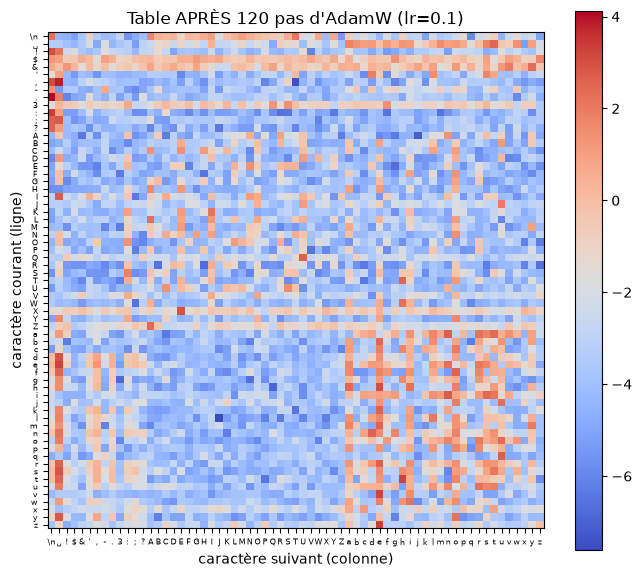

In [13]:
torch.manual_seed(42)
meilleur = modeles["AdamW lr=1e-1"]
print(tok.decode(meilleur.generate(tok.stoi["\n"], 120)))
heatmap(meilleur.token_embedding_table.weight, "Table APRÈS 120 pas d'AdamW (lr=0.1)")

**Ce qu'on observe :** des « mots » de la bonne longueur, des espaces et des retours à la ligne plausibles, des majuscules après `\n`… mais aucun mot réel. Dans la table, on voit apparaître des structures (par exemple, la colonne `␣` est forte pour de nombreuses lignes).

**La limite fondamentale :** le bigramme ne voit **que le dernier caractère**. Après `"th"`, il ne sait pas qu'il y avait un `t` : il ne voit que `h`. Pour aller plus loin, il faut que chaque position puisse **regarder les caractères précédents**. C'est ce que fera l'attention (notebook 05).

## À retenir

- Un modèle = une sous-classe de `nn.Module` : couches dans `__init__`, calcul dans `forward`.
- `nn.Embedding(V, V)` = la matrice `W` du chapitre 1 ; `emb(i)` = `one_hot(i) @ W` = `W[i]`.
- `F.cross_entropy(logits, cibles)` = softmax + `-log p(vraie réponse)` + moyenne, **numériquement stable**. Formes : `(N, V)` et `(N,)`.
- Boucle : `forward` → `zero_grad` → `backward` → `step`.
- **SGD** : pas ∝ gradient, un seul `lr`. **AdamW** : pas normalisé par poids (momentum + amplitude), plus *weight decay* découplé. C'est le standard pour les Transformers.

**Questions de vérification**
1. Pourquoi la loss initiale est-elle supérieure à `log V` ?
2. Que se passerait-il si l'on donnait des probabilités (après softmax) à `F.cross_entropy` ?
3. Pourquoi SGD a-t-il besoin d'un learning rate de 10 ici, alors qu'AdamW se contente de 0.1 ?
4. Pourquoi oublier `optimizer.zero_grad()` fausserait-il l'entraînement ?

**Suite → 03 :** nous allons donner au modèle des **séquences** `(B, T)` au lieu de paires isolées. Cela imposera un *reshape* avant la cross-entropy.

### Références
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) (2023) et son code [ng-video-lecture](https://github.com/karpathy/ng-video-lecture).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003 — l'origine des embeddings pour le langage.
- D. Kingma & J. Ba, [*Adam: A Method for Stochastic Optimization*](https://arxiv.org/abs/1412.6980), ICLR 2015.
- I. Loshchilov & F. Hutter, [*Decoupled Weight Decay Regularization*](https://arxiv.org/abs/1711.05101), ICLR 2019 — AdamW.
- S. Ruder, [*An overview of gradient descent optimization algorithms*](https://arxiv.org/abs/1609.04747), 2016 — très bonne synthèse SGD / momentum / Adam.
- Documentation PyTorch : [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html), [`F.cross_entropy`](https://pytorch.org/docs/stable/generated/torch.nn.functional.cross_entropy.html), [`AdamW`](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html).